# Eksperimen Komparasi & Uji Ablasi Lengkap — Otomatisasi Penggantian Latar Belakang Pas Foto Formal Mahasiswa ITERA
**Kelompok:** Cihuy | **Kelas:** RA | **Topik:** 10  
**Mata Kuliah:** Pengolahan Citra Digital (IF25-40410)  

---

### Daftar Eksperimen dalam Notebook Ini (Bab 5.4)
Notebook ini menyatukan seluruh skenario pengujian pada satu alur kerja yang mendukung **Google Colab (Auto-Mount Google Drive)** maupun **VS Code lokal**:
1. **Model Baseline (`HSV Color Thresholding`):** Segmentasi latar belakang tunggal pada ruang warna HSV tanpa CLAHE, tanpa Sobel, tanpa morfologi lanjutan, dan tanpa *Gaussian Feathering*.
2. **Metode Usulan (`Hybrid HSV/LAB + Sobel + Morfologi + Gaussian Feathering`):** Pipeline lengkap sesuai Bab 4 untuk menghasilkan pas foto formal latar belakang **Merah (`#DB1514`)** dan **Biru (`#0055A4`)**.
3. **Uji Ablasi 1 (`Tanpa Deteksi Tepi Sobel`):** Menghilangkan konvolusi deteksi tepi Sobel untuk mengukur kontribusi penguatan kontur tepi terhadap kualitas masker.
4. **Uji Ablasi 2 (`Tanpa Pembersihan Morfologi Lanjutan & Gaussian Feathering`):** Menghilangkan operasi morfologi (*Closing/Opening/Connected Components/Hole Filling*) dan *feathering* (*hard blending*) untuk mengukur kontribusinya terhadap pengurangan *noise* dan kehalusan tepi.
5. **Komparasi Kuantitatif & Kualitatif Akhir:** Rekapitulasi otomatis tabel metrik (**IoU, Precision, Recall, Dice, Waktu Eksekusi**) beserta visualisasi berdampingan dari keempat model.

In [ ]:
import os
import sys
import json
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['figure.figsize'] = (16, 4.5)
plt.rcParams['axes.titlesize'] = 10

print(f"OpenCV version : {cv2.__version__}")
print(f"NumPy version  : {np.__version__}")

OpenCV version : 5.0.0
NumPy version  : 2.4.6


## 1. Konfigurasi Path Otomatis (Google Colab & Lokal) & Parameter Global
Menjalankan *mount* Google Drive secara otomatis apabila dibuka di **Google Colab**, mencari folder `Dataset`, dan menyiapkan folder output sejajar dengan folder `Dataset`.

In [ ]:
# ==============================================================================
# KONFIGURASI PATH OTOMATIS (MENDUKUNG GOOGLE COLAB & LOKAL VS CODE)
# ==============================================================================
TARGET_WIDTH = 720
TARGET_HEIGHT = 960

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

cwd = Path.cwd()
drive_root = Path("/content/drive/MyDrive")

candidate_dirs = [
    cwd / "Dataset",
    cwd.parent / "Dataset",
    cwd.parent / "Project" / "Dataset",
    drive_root / "Project" / "Dataset",
    drive_root / "Dataset",
]

if IN_COLAB and drive_root.exists():
    candidate_dirs.extend(sorted(drive_root.glob("*/Dataset")))
    candidate_dirs.extend(sorted(drive_root.glob("*/*/Dataset")))

DATASET_DIR = next((p for p in candidate_dirs if p.exists() and p.is_dir()), None)

if DATASET_DIR is None:
    raise FileNotFoundError(
        "Folder 'Dataset' tidak ditemukan. Pastikan folder proyek beserta 'Dataset' "
        "sudah diunggah ke Google Drive (misalnya ke MyDrive/Project/Dataset)."
    )

PROJECT_DIR = DATASET_DIR.parent
RAW_IMG_DIR = DATASET_DIR / "raw"
SPLIT_JSON_PATH = DATASET_DIR / "split.json"
MASK_DIR = DATASET_DIR / "masks"

OUTPUT_DIRS = {
    "baseline": PROJECT_DIR / "output_baseline",
    "proposed": PROJECT_DIR / "output_proposed",
    "ablasi1": PROJECT_DIR / "output_ablasi_1",
    "ablasi2": PROJECT_DIR / "output_ablasi_2",
    "summary": PROJECT_DIR / "output_komparasi"
}

print(f"Environment          : {'Google Colab' if IN_COLAB else 'Lokal'}")
print(f"Project dir          : {PROJECT_DIR.resolve()}")
print(f"Dataset ditemukan di : {DATASET_DIR.resolve()}")
print(f"File split.json      : {SPLIT_JSON_PATH.exists()}")
print(f"Folder ground truth  : {MASK_DIR.exists()}")

# Warna standar latar belakang pas foto formal (dalam format BGR untuk OpenCV)
BG_COLORS_BGR = {
    "merah": (20, 21, 219),   # Merah formal (#DB1514)
    "biru": (164, 85, 0)      # Biru formal (#0055A4)
}

# Parameter Default
DEFAULT_PARAMS = {
    "pre_blur_ksize": (5, 5),
    "clahe_clip_limit": 2.0,
    "clahe_tile_grid": (8, 8),
    "hsv_bg_lower": np.array([0, 0, 165], dtype=np.uint8),
    "hsv_bg_upper": np.array([179, 60, 255], dtype=np.uint8),
    "lab_bg_dist_thresh": 26.0,
    "sobel_ksize": 3,
    "sobel_grad_thresh": 38,
    "morph_open_ksize": (5, 5),
    "morph_close_ksize": (11, 11),
    "feather_blur_ksize": (9, 9),
    "feather_sigma": 2.5
}

Mounted at /content/drive


FileNotFoundError: Folder 'Dataset' tidak ditemukan. Pastikan folder proyek beserta 'Dataset' sudah diunggah ke Google Drive (misalnya ke MyDrive/Project/Dataset).

## 2. Pemuatan Pembagian Dataset (`split.json`) & Utilitas Evaluasi Bersama

In [ ]:
def load_split_paths(split_json_path: Path, raw_dir: Path):
    """Membaca pembagian file dari split.json dan mencocokkannya dengan file di raw/."""
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    raw_by_name = {p.name: p for p in raw_dir.iterdir() if p.suffix.lower() in valid_exts}
    raw_by_stem = {p.stem: p for p in raw_dir.iterdir() if p.suffix.lower() in valid_exts}

    if not split_json_path.exists():
        all_imgs = sorted(raw_by_name.values())
        split_idx = int(len(all_imgs) * 0.8)
        return all_imgs[:split_idx], all_imgs[split_idx:]

    with open(split_json_path, "r", encoding="utf-8") as f:
        splits = json.load(f)

    train_key = next((k for k in splits if any(w in k.lower() for w in ["tun", "train"])), None)
    test_key = next((k for k in splits if any(w in k.lower() for w in ["test", "val"])), None)

    if train_key is None or test_key is None:
        keys = list(splits.keys())
        train_key, test_key = keys[0], (keys[1] if len(keys) > 1 else keys[0])

    def resolve_item(item):
        if isinstance(item, dict):
            raw_val = next((v for k, v in item.items() if k in {"filename", "file", "image", "path", "name", "id"}), str(item))
        else:
            raw_val = str(item)

        p = Path(raw_val)
        if p.name in raw_by_name:
            return raw_by_name[p.name]
        if p.stem in raw_by_stem:
            return raw_by_stem[p.stem]
        return None

    tuning_paths = [res for x in splits[train_key] if (res := resolve_item(x)) is not None]
    testing_paths = [res for x in splits[test_key] if (res := resolve_item(x)) is not None]

    print(f"Tuning set ({train_key}) : {len(tuning_paths)} citra")
    print(f"Testing set ({test_key}) : {len(testing_paths)} citra")
    return tuning_paths, testing_paths


def standardize_image(image: np.ndarray, width: int = TARGET_WIDTH, height: int = TARGET_HEIGHT) -> np.ndarray:
    return cv2.resize(image, (width, height), interpolation=cv2.INTER_AREA)


def compute_iou(pred_mask: np.ndarray, gt_mask: np.ndarray) -> float:
    pred_bool = pred_mask > 127
    gt_bool = gt_mask > 127
    intersection = np.logical_and(pred_bool, gt_bool).sum()
    union = np.logical_or(pred_bool, gt_bool).sum()
    return float(intersection / union) if union > 0 else (1.0 if intersection == 0 else 0.0)


def compute_detailed_metrics(pred_mask: np.ndarray, gt_mask: np.ndarray) -> dict:
    pred = pred_mask > 127
    gt = gt_mask > 127
    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, np.logical_not(gt)).sum()
    fn = np.logical_and(np.logical_not(pred), gt).sum()

    iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 1.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 1.0
    return {"IoU": float(iou), "Precision": float(precision), "Recall": float(recall), "Dice": float(dice)}


tuning_imgs, testing_imgs = load_split_paths(SPLIT_JSON_PATH, RAW_IMG_DIR)

## 3. Definisi Modul Komponen Pemrosesan Citra Digital
Seluruh blok bangunan (*building blocks*) untuk keempat skenario model didefinisikan secara modular agar setiap skenario menggunakan komponen yang konsisten.

In [ ]:
def preprocess_image(image_bgr: np.ndarray, params: dict) -> np.ndarray:
    """Gaussian Blur + CLAHE pada kanal Luminance (L) ruang warna CIELAB."""
    blurred = cv2.GaussianBlur(image_bgr, params["pre_blur_ksize"], 0)
    lab = cv2.cvtColor(blurred, cv2.COLOR_BGR2LAB)
    l_chan, a_chan, b_chan = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=params["clahe_clip_limit"],
        tileGridSize=params["clahe_tile_grid"]
    )
    l_eq = clahe.apply(l_chan)
    return cv2.cvtColor(cv2.merge([l_eq, a_chan, b_chan]), cv2.COLOR_LAB2BGR)


def segment_hsv_only(image_bgr: np.ndarray, params: dict) -> np.ndarray:
    """Segmentasi latar belakang tunggal pada ruang warna HSV (untuk Baseline)."""
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    bg_mask = cv2.inRange(hsv, params["hsv_bg_lower"], params["hsv_bg_upper"])
    return cv2.bitwise_not(bg_mask)


def segment_hsv_lab_hybrid(enhanced_bgr: np.ndarray, params: dict) -> np.ndarray:
    """Segmentasi warna multi-ruang HSV + jarak Euclidean pada CIELAB."""
    hsv = cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2HSV)
    bg_mask_hsv = cv2.inRange(hsv, params["hsv_bg_lower"], params["hsv_bg_upper"])

    lab = cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    h, w, _ = lab.shape
    border_patches = np.concatenate([
        lab[0:25, 0:60].reshape(-1, 3),
        lab[0:25, w-60:w].reshape(-1, 3),
        lab[0:15, w//4:3*w//4].reshape(-1, 3)
    ], axis=0)
    bg_ref_lab = np.median(border_patches, axis=0)

    color_dist = np.linalg.norm(lab - bg_ref_lab, axis=-1)
    bg_mask_lab = (color_dist < params["lab_bg_dist_thresh"]).astype(np.uint8) * 255

    combined_bg = cv2.bitwise_or(bg_mask_hsv, bg_mask_lab)
    return cv2.bitwise_not(combined_bg)


def sobel_edge_refinement(enhanced_bgr: np.ndarray, params: dict) -> np.ndarray:
    """Konvolusi deteksi tepi spasial menggunakan operator Sobel."""
    gray = cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2GRAY)
    ksize = params["sobel_ksize"]

    grad_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=ksize)
    grad_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=ksize)

    grad_mag = cv2.magnitude(grad_x, grad_y)
    grad_norm = cv2.normalize(grad_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    _, sobel_edges = cv2.threshold(grad_norm, params["sobel_grad_thresh"], 255, cv2.THRESH_BINARY)
    return sobel_edges


def fuse_color_and_sobel(initial_fg_mask: np.ndarray, sobel_edges: np.ndarray) -> np.ndarray:
    """Fusi masker warna dan kontur tepi Sobel menggunakan operasi logika Boolean."""
    dilated_region = cv2.dilate(initial_fg_mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)))
    valid_edges = cv2.bitwise_and(sobel_edges, dilated_region)
    return cv2.bitwise_or(initial_fg_mask, valid_edges)


def morphology_cleanup(mask: np.ndarray, params: dict) -> np.ndarray:
    """Morphological Closing, Opening, Largest Connected Component, dan Contour Hole Filling."""
    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, params["morph_close_ksize"])
    kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, params["morph_open_ksize"])

    closed_mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)
    opened_mask = cv2.morphologyEx(closed_mask, cv2.MORPH_OPEN, kernel_open)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(opened_mask, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        subject_mask = np.where(labels == largest_label, 255, 0).astype(np.uint8)
    else:
        subject_mask = opened_mask

    contours, _ = cv2.findContours(subject_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    clean_binary_mask = np.zeros_like(subject_mask)
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        cv2.drawContours(clean_binary_mask, [largest_contour], -1, 255, thickness=cv2.FILLED)

    return clean_binary_mask


def replace_background_hard(image_bgr: np.ndarray, fg_mask: np.ndarray, bg_color_name: str = "merah") -> np.ndarray:
    """Penggantian latar belakang biner keras (tanpa Gaussian Feathering)."""
    bg_color = BG_COLORS_BGR[bg_color_name.lower()]
    result = np.full_like(image_bgr, bg_color, dtype=np.uint8)
    fg_bool = fg_mask > 127
    result[fg_bool] = image_bgr[fg_bool]
    return result


def gaussian_edge_blending(image_bgr: np.ndarray, clean_binary_mask: np.ndarray, bg_color_name: str = "merah", params: dict = DEFAULT_PARAMS):
    """Penghalusan tepi (Gaussian Feathering) & Alpha Blending."""
    erode_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    eroded_mask = cv2.erode(clean_binary_mask, erode_kernel, iterations=1)

    soft_mask = cv2.GaussianBlur(
        eroded_mask,
        params["feather_blur_ksize"],
        params["feather_sigma"]
    )
    alpha = (soft_mask.astype(np.float32) / 255.0)[..., np.newaxis]

    bg_color = np.array(BG_COLORS_BGR[bg_color_name.lower()], dtype=np.float32)
    fg_float = image_bgr.astype(np.float32)
    blended = (alpha * fg_float + (1.0 - alpha) * bg_color).clip(0, 255).astype(np.uint8)
    return soft_mask, blended

## 4. Definisi Keempat Skenario Pipeline
- **`run_baseline_single`**: Standarisasi $\rightarrow$ HSV Thresholding $\rightarrow$ Hard Blending.
- **`run_proposed_single`**: Standarisasi $\rightarrow$ Blur+CLAHE $\rightarrow$ HSV+LAB $\rightarrow$ Sobel $\rightarrow$ Morfologi $\rightarrow$ Gaussian Feathering.
- **`run_ablasi1_single`**: Standarisasi $\rightarrow$ Blur+CLAHE $\rightarrow$ HSV+LAB $\rightarrow$ **(Tanpa Sobel)** $\rightarrow$ Morfologi $\rightarrow$ Gaussian Feathering.
- **`run_ablasi2_single`**: Standarisasi $\rightarrow$ Blur+CLAHE $\rightarrow$ HSV+LAB $\rightarrow$ Sobel $\rightarrow$ **(Tanpa Morfologi Lanjutan & Tanpa Feathering)** $\rightarrow$ Hard Blending.

In [ ]:
def run_baseline_single(image_bgr: np.ndarray, bg_color_name: str = "merah", params: dict = DEFAULT_PARAMS):
    t0 = time.perf_counter()
    std_img = standardize_image(image_bgr)
    fg_mask = segment_hsv_only(std_img, params)
    out_merah = replace_background_hard(std_img, fg_mask, "merah")
    elapsed = time.perf_counter() - t0
    out_biru = replace_background_hard(std_img, fg_mask, "biru")
    return {
        "std_img": std_img,
        "fg_mask": fg_mask,
        "output_merah": out_merah if bg_color_name == "merah" else out_biru,
        "output_biru": out_biru,
        "time_sec": elapsed
    }


def run_proposed_single(image_bgr: np.ndarray, bg_color_name: str = "merah", params: dict = DEFAULT_PARAMS):
    t0 = time.perf_counter()
    std_img = standardize_image(image_bgr)
    enhanced = preprocess_image(std_img, params)
    initial_mask = segment_hsv_lab_hybrid(enhanced, params)
    sobel_edges = sobel_edge_refinement(enhanced, params)
    fused_mask = fuse_color_and_sobel(initial_mask, sobel_edges)
    clean_mask = morphology_cleanup(fused_mask, params)
    _, out_merah = gaussian_edge_blending(std_img, clean_mask, "merah", params)
    elapsed = time.perf_counter() - t0
    _, out_biru = gaussian_edge_blending(std_img, clean_mask, "biru", params)
    return {
        "std_img": std_img,
        "enhanced_img": enhanced,
        "initial_mask": initial_mask,
        "sobel_edges": sobel_edges,
        "fg_mask": clean_mask,
        "output_merah": out_merah,
        "output_biru": out_biru,
        "time_sec": elapsed
    }


def run_ablasi1_single(image_bgr: np.ndarray, bg_color_name: str = "merah", params: dict = DEFAULT_PARAMS):
    """Ablasi 1: Tanpa deteksi tepi Sobel."""
    t0 = time.perf_counter()
    std_img = standardize_image(image_bgr)
    enhanced = preprocess_image(std_img, params)
    initial_mask = segment_hsv_lab_hybrid(enhanced, params)
    clean_mask = morphology_cleanup(initial_mask, params)
    _, out_merah = gaussian_edge_blending(std_img, clean_mask, "merah", params)
    elapsed = time.perf_counter() - t0
    _, out_biru = gaussian_edge_blending(std_img, clean_mask, "biru", params)
    return {
        "std_img": std_img,
        "fg_mask": clean_mask,
        "output_merah": out_merah,
        "output_biru": out_biru,
        "time_sec": elapsed
    }


def run_ablasi2_single(image_bgr: np.ndarray, bg_color_name: str = "merah", params: dict = DEFAULT_PARAMS):
    """Ablasi 2: Tanpa operasi morfologi lanjutan & tanpa Gaussian Feathering."""
    t0 = time.perf_counter()
    std_img = standardize_image(image_bgr)
    enhanced = preprocess_image(std_img, params)
    initial_mask = segment_hsv_lab_hybrid(enhanced, params)
    sobel_edges = sobel_edge_refinement(enhanced, params)
    raw_fused_mask = fuse_color_and_sobel(initial_mask, sobel_edges)
    out_merah = replace_background_hard(std_img, raw_fused_mask, "merah")
    elapsed = time.perf_counter() - t0
    out_biru = replace_background_hard(std_img, raw_fused_mask, "biru")
    return {
        "std_img": std_img,
        "fg_mask": raw_fused_mask,
        "output_merah": out_merah,
        "output_biru": out_biru,
        "time_sec": elapsed
    }

## 5. Kalibrasi Hyperparameter pada Tuning Set (Opsional)

In [ ]:
def tune_parameters(tuning_imgs: list[Path], mask_dir: Path, base_params: dict = DEFAULT_PARAMS) -> dict:
    tuned = dict(base_params)
    has_masks = mask_dir.exists() and any(len(list(mask_dir.glob(f"{p.stem}.*"))) > 0 for p in tuning_imgs)
    if not tuning_imgs or not has_masks:
        print("Ground truth mask pada tuning set belum tersedia — menggunakan DEFAULT_PARAMS.")
        return tuned

    best_iou = -1.0
    best_cfg = (tuned["lab_bg_dist_thresh"], tuned["sobel_grad_thresh"])
    for lab_thresh in [20.0, 26.0, 32.0, 38.0]:
        for sobel_thresh in [30, 38, 48]:
            trial = dict(tuned)
            trial["lab_bg_dist_thresh"] = lab_thresh
            trial["sobel_grad_thresh"] = sobel_thresh
            ious = []
            for img_path in tuning_imgs:
                mask_candidates = list(mask_dir.glob(f"{img_path.stem}.*"))
                if not mask_candidates:
                    continue
                img = cv2.imread(str(img_path))
                gt = standardize_image(cv2.imread(str(mask_candidates[0]), cv2.IMREAD_GRAYSCALE))
                res = run_proposed_single(img, params=trial)
                ious.append(compute_iou(res["fg_mask"], gt))
            if ious and np.mean(ious) > best_iou:
                best_iou = float(np.mean(ious))
                best_cfg = (lab_thresh, sobel_thresh)

    tuned["lab_bg_dist_thresh"], tuned["sobel_grad_thresh"] = best_cfg
    print(f"Tuning selesai | Best Mean IoU: {best_iou:.4f} | lab_bg_dist_thresh={best_cfg[0]}, sobel_grad_thresh={best_cfg[1]}")
    return tuned

TUNED_PARAMS = tune_parameters(tuning_imgs, MASK_DIR, DEFAULT_PARAMS)

## 6. Eksekusi & Evaluasi Kuantitatif Keempat Model pada Testing Set
Menjalankan seluruh model (**Baseline**, **Metode Usulan**, **Ablasi 1**, dan **Ablasi 2**) pada `testing_imgs`, menyimpan hasil gambar (latar Merah, latar Biru, dan *mask*) serta file `.csv` metrik ke Google Drive.

In [ ]:
def evaluate_model_on_dataset(
    model_name: str,
    runner_fn,
    testing_imgs: list[Path],
    mask_dir: Path,
    output_dir: Path,
    csv_filename: str,
    params: dict = TUNED_PARAMS
) -> pd.DataFrame:
    output_dir.mkdir(parents=True, exist_ok=True)
    (output_dir / "masks").mkdir(exist_ok=True)
    (output_dir / "results_merah").mkdir(exist_ok=True)
    (output_dir / "results_biru").mkdir(exist_ok=True)

    records = []
    for img_path in testing_imgs:
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            continue

        res = runner_fn(img_bgr, bg_color_name="merah", params=params)

        cv2.imwrite(str(output_dir / "masks" / f"{img_path.stem}_mask.png"), res["fg_mask"])
        cv2.imwrite(str(output_dir / "results_merah" / f"{img_path.stem}_merah.jpg"), res["output_merah"])
        cv2.imwrite(str(output_dir / "results_biru" / f"{img_path.stem}_biru.jpg"), res["output_biru"])

        gt_candidates = list(mask_dir.glob(f"{img_path.stem}.*")) if mask_dir.exists() else []
        if gt_candidates:
            gt_mask = standardize_image(cv2.imread(str(gt_candidates[0]), cv2.IMREAD_GRAYSCALE))
            metrics = compute_detailed_metrics(res["fg_mask"], gt_mask)
        else:
            metrics = {"IoU": np.nan, "Precision": np.nan, "Recall": np.nan, "Dice": np.nan}

        records.append({
            "Model": model_name,
            "Filename": img_path.name,
            **metrics,
            "Time_sec": res["time_sec"]
        })

    df = pd.DataFrame(records)
    df.to_csv(output_dir / csv_filename, index=False)
    return df


df_baseline = evaluate_model_on_dataset(
    "Baseline (HSV)", run_baseline_single, testing_imgs, MASK_DIR,
    OUTPUT_DIRS["baseline"], "baseline_evaluation_metrics.csv", TUNED_PARAMS
)

df_proposed = evaluate_model_on_dataset(
    "Metode Usulan (Full Hybrid)", run_proposed_single, testing_imgs, MASK_DIR,
    OUTPUT_DIRS["proposed"], "proposed_evaluation_metrics.csv", TUNED_PARAMS
)

df_ablasi1 = evaluate_model_on_dataset(
    "Ablasi 1 (Tanpa Sobel)", run_ablasi1_single, testing_imgs, MASK_DIR,
    OUTPUT_DIRS["ablasi1"], "ablasi1_evaluation_metrics.csv", TUNED_PARAMS
)

df_ablasi2 = evaluate_model_on_dataset(
    "Ablasi 2 (Tanpa Morfologi & Feathering)", run_ablasi2_single, testing_imgs, MASK_DIR,
    OUTPUT_DIRS["ablasi2"], "ablasi2_evaluation_metrics.csv", TUNED_PARAMS
)

print("Evaluasi keempat model selesai dan seluruh output telah tersimpan.")

## 7. Tabel Rekapitulasi & Grafik Perbandingan Kuantitatif (Bab 5.4)

In [ ]:
all_dfs = [df_baseline, df_proposed, df_ablasi1, df_ablasi2]
summary_rows = []

for df in all_dfs:
    if df.empty:
        continue
    summary_rows.append({
        "Model": df["Model"].iloc[0],
        "Jumlah Citra": len(df),
        "Mean IoU": df["IoU"].mean(),
        "Mean Precision": df["Precision"].mean(),
        "Mean Recall": df["Recall"].mean(),
        "Mean Dice": df["Dice"].mean(),
        "Rata-rata Waktu (ms)": df["Time_sec"].mean() * 1000.0
    })

df_summary = pd.DataFrame(summary_rows)
OUTPUT_DIRS["summary"].mkdir(parents=True, exist_ok=True)
df_summary.to_csv(OUTPUT_DIRS["summary"] / "rekapitulasi_perbandingan_4_model.csv", index=False)

display(df_summary.style.format({
    "Mean IoU": "{:.4f}",
    "Mean Precision": "{:.4f}",
    "Mean Recall": "{:.4f}",
    "Mean Dice": "{:.4f}",
    "Rata-rata Waktu (ms)": "{:.2f}"
}))

# Grafik Perbandingan Waktu & Akurasi
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
models_short = ["Baseline", "Usulan", "Ablasi 1\n(No Sobel)", "Ablasi 2\n(No Morph/Feather)"]
colors = ["#7f8c8d", "#27ae60", "#2980b9", "#e67e22"]

if not df_summary["Mean IoU"].isna().all():
    bars1 = axes[0].bar(models_short, df_summary["Mean IoU"], color=colors)
    axes[0].axhline(0.80, color="red", linestyle="--", linewidth=1, label="Target IoU (0.80)")
    axes[0].set_ylim(0, 1.05)
    axes[0].set_title("Perbandingan Rata-rata IoU")
    axes[0].set_ylabel("IoU")
    axes[0].legend()
    for b in bars1:
        h = b.get_height()
        if not np.isnan(h):
            axes[0].text(b.get_x() + b.get_width()/2, h + 0.02, f"{h:.3f}", ha="center", fontsize=9)
else:
    axes[0].text(0.5, 0.5, "Ground Truth Mask belum tersedia\n(IoU akan tampil setelah folder masks/ diisi)", ha="center", va="center")
    axes[0].set_title("Perbandingan Rata-rata IoU")

bars2 = axes[1].bar(models_short, df_summary["Rata-rata Waktu (ms)"], color=colors)
axes[1].set_title("Perbandingan Waktu Komputasi Rata-rata (ms/citra)")
axes[1].set_ylabel("Waktu (ms)")
for b in bars2:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2, h + 0.5, f"{h:.1f} ms", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIRS["summary"] / "grafik_perbandingan_4_model.png", dpi=200)
plt.show()

## 8. Visualisasi Kualitatif Berdampingan (Input vs Baseline vs Usulan vs Ablasi 1 vs Ablasi 2)

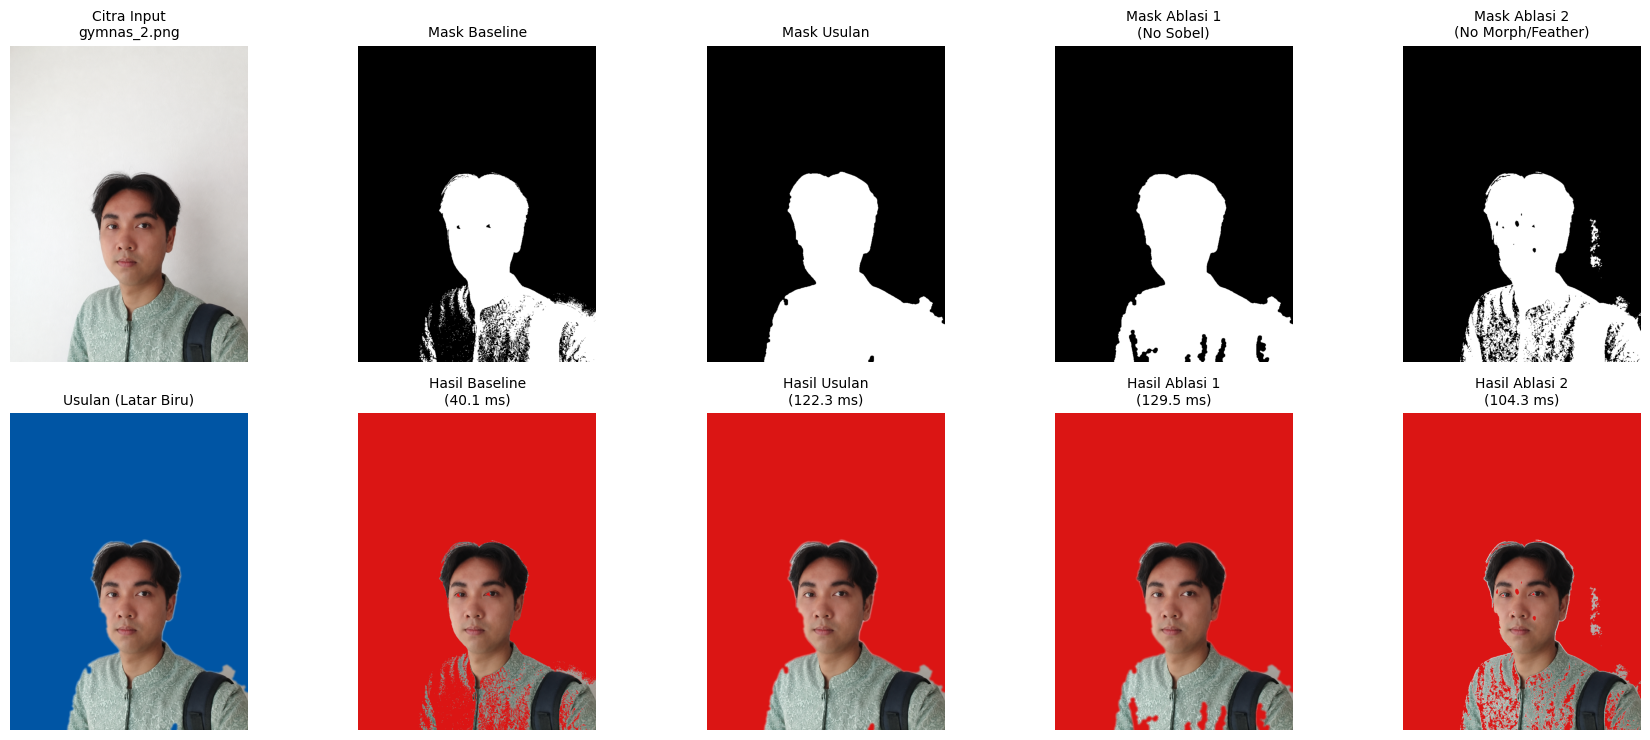

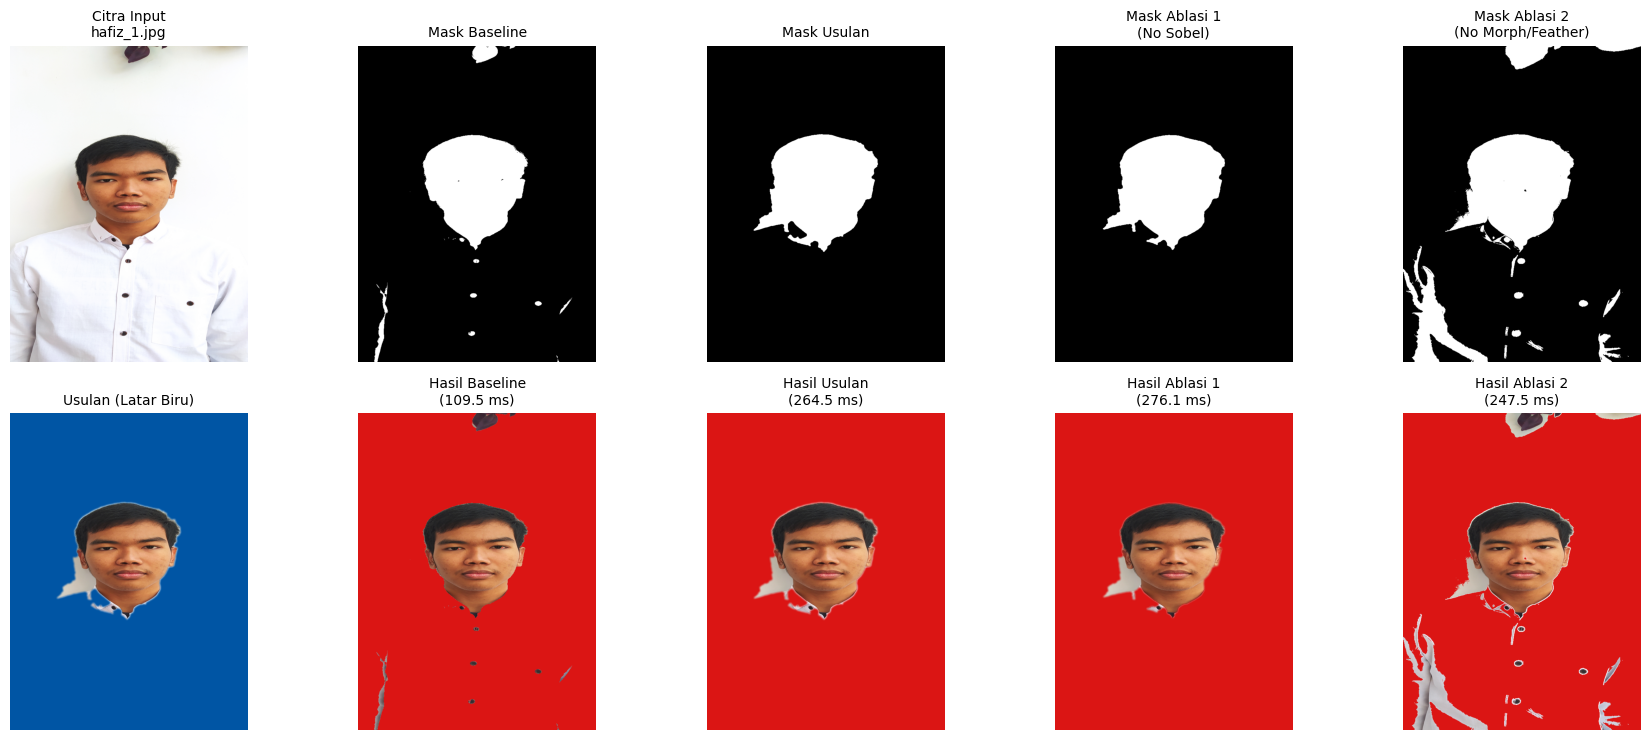

In [12]:
def visualize_side_by_side_comparison(
    testing_imgs: list[Path],
    mask_dir: Path,
    num_samples: int = 3,
    bg_color: str = "merah",
    params: dict = TUNED_PARAMS
):
    for img_path in testing_imgs[:num_samples]:
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            continue

        res_base = run_baseline_single(img_bgr, bg_color, params)
        res_prop = run_proposed_single(img_bgr, bg_color, params)
        res_ab1 = run_ablasi1_single(img_bgr, bg_color, params)
        res_ab2 = run_ablasi2_single(img_bgr, bg_color, params)

        gt_candidates = list(mask_dir.glob(f"{img_path.stem}.*")) if mask_dir.exists() else []
        gt_mask = standardize_image(cv2.imread(str(gt_candidates[0]), cv2.IMREAD_GRAYSCALE)) if gt_candidates else None

        def fmt_title(label, mask):
            if gt_mask is not None:
                return f"{label}\nIoU: {compute_iou(mask, gt_mask):.4f}"
            return label

        # Baris 1: Masker Segmentasi | Baris 2: Hasil Penggantian Background
        fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))

        # Baris 1 (Masks)
        axes[0, 0].imshow(cv2.cvtColor(res_prop["std_img"], cv2.COLOR_BGR2RGB))
        axes[0, 0].set_title(f"Citra Input\n{img_path.name}")

        axes[0, 1].imshow(res_base["fg_mask"], cmap="gray", vmin=0, vmax=255)
        axes[0, 1].set_title(fmt_title("Mask Baseline", res_base["fg_mask"]))

        axes[0, 2].imshow(res_prop["fg_mask"], cmap="gray", vmin=0, vmax=255)
        axes[0, 2].set_title(fmt_title("Mask Usulan", res_prop["fg_mask"]))

        axes[0, 3].imshow(res_ab1["fg_mask"], cmap="gray", vmin=0, vmax=255)
        axes[0, 3].set_title(fmt_title("Mask Ablasi 1\n(No Sobel)", res_ab1["fg_mask"]))

        axes[0, 4].imshow(res_ab2["fg_mask"], cmap="gray", vmin=0, vmax=255)
        axes[0, 4].set_title(fmt_title("Mask Ablasi 2\n(No Morph/Feather)", res_ab2["fg_mask"]))

        # Baris 2 (Output Background)
        out_key = "output_merah" if bg_color == "merah" else "output_biru"
        axes[1, 0].imshow(cv2.cvtColor(res_prop["output_biru"], cv2.COLOR_BGR2RGB))
        axes[1, 0].set_title("Usulan (Latar Biru)")

        axes[1, 1].imshow(cv2.cvtColor(res_base[out_key], cv2.COLOR_BGR2RGB))
        axes[1, 1].set_title(f"Hasil Baseline\n({res_base['time_sec']*1000:.1f} ms)")

        axes[1, 2].imshow(cv2.cvtColor(res_prop[out_key], cv2.COLOR_BGR2RGB))
        axes[1, 2].set_title(f"Hasil Usulan\n({res_prop['time_sec']*1000:.1f} ms)")

        axes[1, 3].imshow(cv2.cvtColor(res_ab1[out_key], cv2.COLOR_BGR2RGB))
        axes[1, 3].set_title(f"Hasil Ablasi 1\n({res_ab1['time_sec']*1000:.1f} ms)")

        axes[1, 4].imshow(cv2.cvtColor(res_ab2[out_key], cv2.COLOR_BGR2RGB))
        axes[1, 4].set_title(f"Hasil Ablasi 2\n({res_ab2['time_sec']*1000:.1f} ms)")

        for ax in axes.ravel():
            ax.axis("off")

        plt.tight_layout()
        plt.savefig(OUTPUT_DIRS["summary"] / f"komparasi_{img_path.stem}.png", dpi=180)
        plt.show()

visualize_side_by_side_comparison(testing_imgs, MASK_DIR, num_samples=3, bg_color="merah")